In [1]:
from pathlib import Path

accession = "PF24444"

phmm_dir = Path("results/phmm/n")
hqmm_dir = Path("results/phqmm/n")
output_dir = Path("results/comparison")
output_dir.mkdir(parents=True, exist_ok=True)

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def load_histories(directory, accession):
    histories = {}

    for path in sorted(directory.glob(
        f"{accession}_m*_history.csv"
    )):
        match = re.search(r"_m(\d+)_", path.name)

        if match is None:
            continue

        match_len = int(match.group(1))

        if match_len in histories:
            raise ValueError(
                f"Multiple histories for match_len={match_len} "
                f"in {directory}. Select one configuration first."
            )

        histories[match_len] = pd.read_csv(path)

    return histories


phmm_histories = load_histories(phmm_dir, accession)
hqmm_histories = load_histories(hqmm_dir, accession)

print("PHMM match lengths:", sorted(phmm_histories))
print("HQMM match lengths:", sorted(hqmm_histories))

PHMM match lengths: [29, 34, 39]
HQMM match lengths: [29, 34, 39]


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def plot_learning_curves(
    phmm_histories,
    hqmm_histories,
    x="iter",
    out_dir=None,
    accession=None
):
    """
    Plot PHQMM vs PHMM learning curves for each match length.

    Solid lines  : Validation DA
    Dashed lines : Training DA
    Shaded bands : Validation DA ± 1 std

    Parameters
    ----------
    phmm_histories, hqmm_histories : dict
        Dictionaries mapping match lengths to DataFrames.

    x : str
        "iter" - DA vs iteration/epoch
        "time" - DA vs training time

    out_dir : str or Path, optional
        Directory for saving figures.

    accession : str, optional
        Protein family accession for filenames.
    """

    if x not in ("iter", "time"):
        raise ValueError("x must be 'iter' or 'time'")

    match_lengths = sorted(
        set(phmm_histories) & set(hqmm_histories),
        reverse=True
    )

    if not match_lengths:
        raise ValueError("No common match lengths found.")

    if out_dir is not None:
        out_dir = Path(out_dir)
        out_dir.mkdir(parents=True, exist_ok=True)

    for m in match_lengths:
        fig, ax = plt.subplots(figsize=(8, 5))

        for model_name, histories, color in [
            ("PHMM", phmm_histories, "C0"),
            ("PHQMM", hqmm_histories, "C1")
        ]:
            hist = histories[m]

            # Select horizontal axis
            if x == "iter":
                x_values = hist["iter"].to_numpy(
                    dtype=float
                )
            else:
                if "train_time" in hist.columns:
                    time_col = "train_time"
                elif "cpu_time" in hist.columns:
                    time_col = "cpu_time"
                else:
                    raise ValueError(
                        f"No training-time column for "
                        f"{model_name}, m={m}"
                    )

                x_values = hist[time_col].to_numpy(
                    dtype=float
                )

            # Training DA
            train_mean = hist["train_da_mean"].to_numpy(
                dtype=float
            )

            # Validation DA
            val_mean = hist["val_da_mean"].to_numpy(
                dtype=float
            )
            val_std = hist["val_da_std"].to_numpy(
                dtype=float
            )

            # Training DA: dashed line
            ax.plot(
                x_values,
                train_mean,
                color=color,
                linestyle="--",
                linewidth=1.8,
                label=f"{model_name} (Training)"
            )

            # Validation DA: solid line
            ax.plot(
                x_values,
                val_mean,
                color=color,
                linestyle="-",
                linewidth=2,
                label=f"{model_name} (Validation)"
            )

            # Validation DA standard deviation
            ax.fill_between(
                x_values,
                val_mean - val_std,
                val_mean + val_std,
                color=color,
                alpha=0.12
            )

        ax.set_xlabel(
            "Training Iteration / Epoch"
            if x == "iter"
            else "Recorded Training Time (s)"
        )

        ax.set_ylabel(
            "Description Accuracy (DA)"
        )

        ax.set_title(
            f"PHQMM vs PHMM — m={m}"
        )

        ax.legend()
        ax.grid(alpha=0.25)

        fig.tight_layout()

        if out_dir is not None:
            axis_label = (
                "epoch" if x == "iter" else "time"
            )

            prefix = (
                f"{accession}_"
                if accession is not None
                else ""
            )

            fig.savefig(
                out_dir / (
                    f"{prefix}m{m}_phqmm_vs_phmm_"
                    f"da_vs_{axis_label}.png"
                ),
                dpi=300,
                bbox_inches="tight"
            )

        plt.show()
        plt.close(fig)

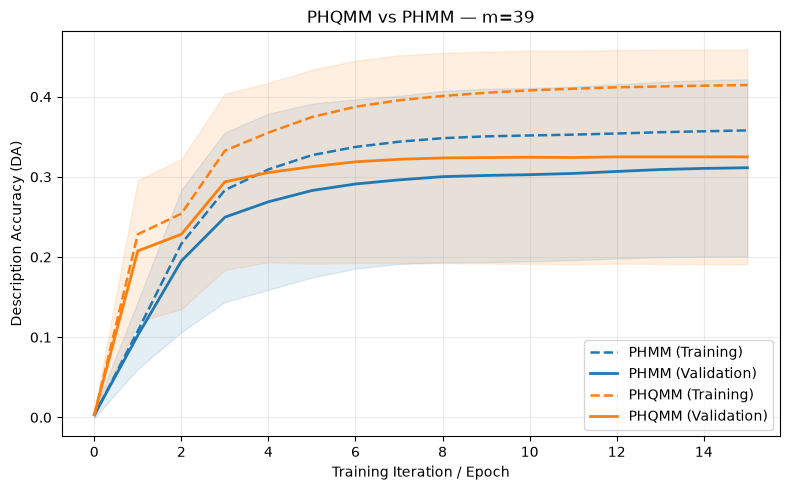

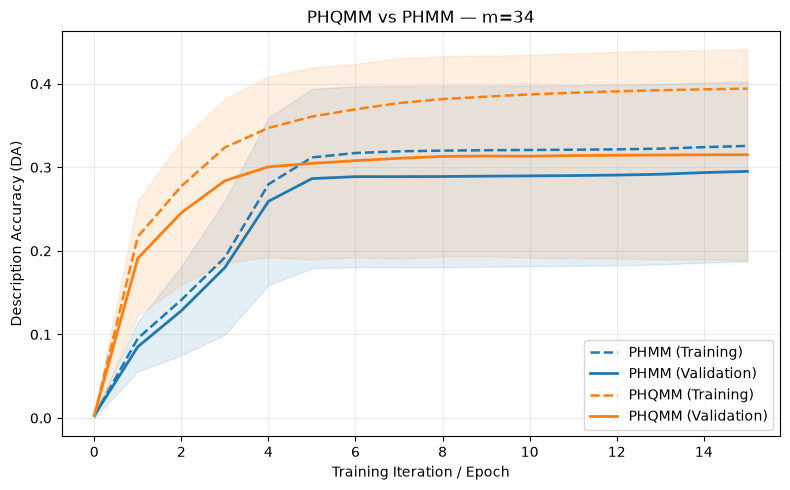

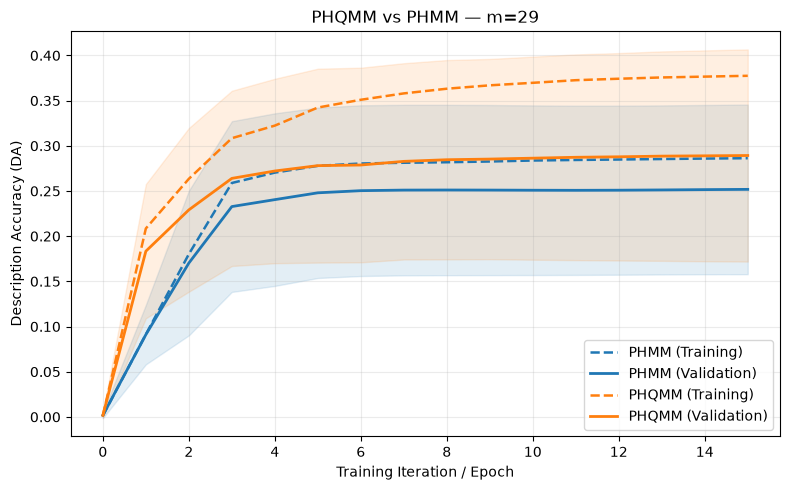

In [4]:
plot_learning_curves(
    phmm_histories,
    hqmm_histories,
    x="iter",
    out_dir=output_dir,
    accession=accession
)

In [5]:

def get_final_da(histories, test_csv=None):
    results = {}

    for m, hist in histories.items():
        # Model selected by highest validation DA
        best_row = hist.loc[hist["val_da_mean"].idxmax()]

        results[int(m)] = {
            "train_da_mean": best_row["train_da_mean"],
            "train_da_std": best_row["train_da_std"],
            "val_da_mean": best_row["val_da_mean"],
            "val_da_std": best_row["val_da_std"],
        }

    df = pd.DataFrame.from_dict(
        results, orient="index"
    ).rename_axis("match_len")

    # Add final test DA only if provided
    if test_csv is not None:
        test_df = pd.read_csv(test_csv)

        required = {
            "match_len",
            "trained_da_mean",
            "trained_da_std"
        }

        missing = required - set(test_df.columns)
        if missing:
            raise ValueError(
                f"Missing columns in {test_csv}: {missing}"
            )

        if test_df["match_len"].duplicated().any():
            raise ValueError(
                f"Duplicate match lengths in {test_csv}"
            )

        test_df = (
            test_df
            .set_index("match_len")
            .rename(columns={
                "trained_da_mean": "test_da_mean",
                "trained_da_std": "test_da_std"
            })
        )

        df = df.join(
            test_df[["test_da_mean", "test_da_std"]]
        )

    return df

def plot_final_da(
    phmm_results,
    hqmm_results,
    metrics=["test"],
    out=None
):
    """
    Compare PHMM and PHQMM DA across match lengths.

    metrics : list
        Any combination of ["train", "val", "test"].

    Match lengths are arranged from lowest to highest.
    """

    valid_metrics = {"train", "val", "test"}

    if (
        not metrics
        or len(set(metrics)) != len(metrics)
        or any(m not in valid_metrics for m in metrics)
    ):
        raise ValueError(
            "metrics must contain unique values from "
            "['train', 'val', 'test']"
        )

    # Ascending match lengths
    lengths = sorted(
        set(phmm_results.index) & set(hqmm_results.index)
    )

    if not lengths:
        raise ValueError("No matching model lengths found.")

    metric_labels = {
        "train": "Training",
        "val": "Validation",
        "test": "Test"
    }

    model_data = [
        ("PHMM", phmm_results, "C0"),
        ("PHQMM", hqmm_results, "C1")
    ]

    # Verify requested metrics exist
    for name, df, _ in model_data:
        required = {
            f"{metric}_da_{stat}"
            for metric in metrics
            for stat in ("mean", "std")
        }

        missing = required - set(df.columns)

        if missing:
            raise ValueError(
                f"{name} results missing: {sorted(missing)}"
            )

        if df.loc[lengths, list(required)].isna().any().any():
            raise ValueError(
                f"{name} has missing DA values."
            )

    x = np.arange(len(lengths))
    n_bars = len(metrics) * 2
    width = 0.8 / n_bars

    fig, ax = plt.subplots(figsize=(9, 5.5))

    hatch_styles = {
        "train": "//",
        "val": "..",
        "test": ""
    }

    for metric_idx, metric in enumerate(metrics):

        for model_idx, (name, df, color) in enumerate(
            model_data
        ):
            rows = df.loc[lengths]

            mean = rows[
                f"{metric}_da_mean"
            ].to_numpy(dtype=float)

            std = rows[
                f"{metric}_da_std"
            ].to_numpy(dtype=float)

            bar_idx = metric_idx * 2 + model_idx
            offset = (
                bar_idx - (n_bars - 1) / 2
            ) * width

            ax.bar(
                x + offset,
                mean,
                width,
                yerr=std,
                capsize=3,
                color=color,
                hatch=hatch_styles[metric],
                edgecolor="black",
                linewidth=0.5,
                label=f"{name} ({metric_labels[metric]})"
            )

    ax.set_xticks(x)
    ax.set_xticklabels([f"m={m}" for m in lengths])

    ax.set_xlabel("Profile Match Length")
    ax.set_ylabel("Description Accuracy (DA)")

    title_metrics = ", ".join(
        metric_labels[m] for m in metrics
    )

    ax.set_title(
        f"PHQMM vs PHMM — {title_metrics} DA"
    )

    ax.legend(ncol=2, fontsize=9)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    fig.tight_layout()

    if out is not None:
        out = Path(out)
        out.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            out,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()
    plt.close(fig)

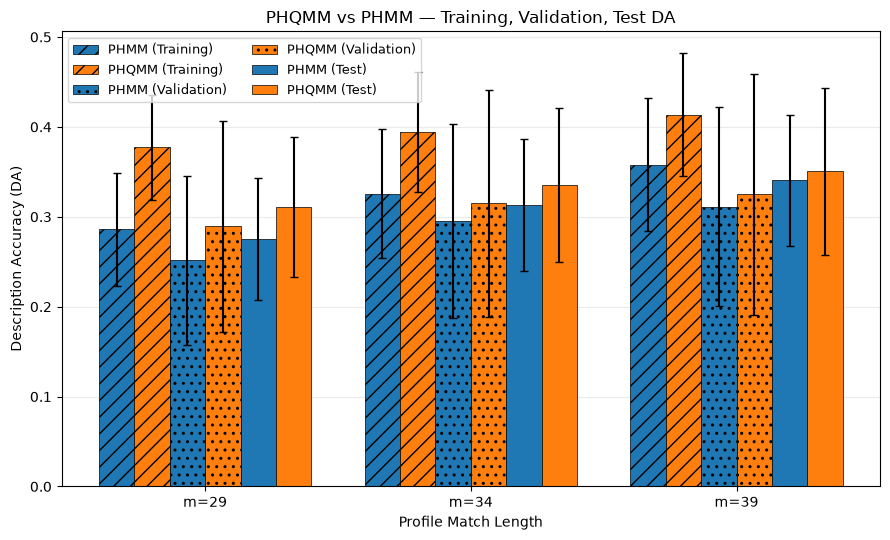

In [6]:
phmm_results = get_final_da(
    phmm_histories,
    test_csv=phmm_dir / f"{accession}_match_len_comparison.csv"
)

hqmm_results = get_final_da(
    hqmm_histories,
    test_csv=hqmm_dir / f"{accession}_match_len_comparison.csv"
)

plot_final_da(
    phmm_results,
    hqmm_results,
    metrics=["train", "val", "test"],
    out=output_dir / f"{accession}_all_da.png"
)